# RGT-Est on Google Colab: Poseidon test

Runs the pretrained RGT-Est model (Dou, Wu, Gao & Bi, 2026) on the Poseidon seismic survey.

**Before you start**
1. **Runtime → Change runtime type → GPU** (a T4 is the minimum; pick L4 or A100 if you have access).
2. Upload these two files into the Colab session: open the **Files** panel (folder icon on the left) and drag them into the top-level `content` folder:
   - `RGT-Est_CIG-Benchmark.pt` (the pretrained model)
   - your Poseidon file, e.g. `Poseidon_part2.npy`

   Wait for the upload progress circle at the bottom of the Files panel to finish before running anything.

Then run the cells from top to bottom (**Runtime → Run all**).

**Note:** files in the Colab session are deleted when the runtime disconnects or is reset, so you will need to upload them again in a new session. Download anything you want to keep (step 6 has a download button for the result).

## 1. Settings: change these if your files are named or placed differently

In [3]:
DATA_FOLDER  = "/content"                 # where you uploaded the files
MODEL_FILE   = "RGT-Est_CIG-Benchmark.pt"
SEIS_FILE    = "Poseidon_part2.npy"      # or Poseidon_part1.npy
OUTPUT_FILE  = "Poseidon_RGT.npy"         # the result is saved in the same folder

## 2. Check the GPU and the uploaded files

In [4]:
import torch
print("PyTorch", torch.__version__)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0),
          f"({torch.cuda.get_device_properties(0).total_memory/1e9:.0f} GB)")
else:
    print("No GPU found. Go to Runtime → Change runtime type → GPU, then run again.")

import os
missing = []
for f in (MODEL_FILE, SEIS_FILE):
    p = os.path.join(DATA_FOLDER, f)
    if os.path.exists(p):
        print(f"found    {p}  ({os.path.getsize(p)/1e6:.0f} MB)")
    else:
        print(f"MISSING  {p}"); missing.append(f)
if missing:
    raise FileNotFoundError("Upload the missing file(s) into the Files panel (left sidebar), "
                            "or fix the names in the Settings cell, then run this cell again.")

PyTorch 2.11.0+cu130
GPU: NVIDIA L4 (24 GB)
found    /content/RGT-Est_CIG-Benchmark.pt  (309 MB)
found    /content/Poseidon_part2.npy  (319 MB)


## 3. Get the RGT-Est code (your fork)

In [5]:
!git clone -q https://github.com/fergusrssmith/RGT /content/RGT 2>/dev/null || git -C /content/RGT pull -q
import sys
sys.path.insert(0, "/content/RGT/demo")

## 4. Load and normalise the seismic

In [6]:
import numpy as np
import torch.nn as nn
import torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"

def normalization(data):
    rng = np.max(data) - np.min(data)
    return (data - np.min(data)) / (rng + 1e-6)

def z_score_clip(data, clp_s=3.0):
    z = (data - np.mean(data)) / (np.std(data) + 1e-8)
    return normalization(np.clip(z, -clp_s, clp_s))

raw = np.load(os.path.join(DATA_FOLDER, SEIS_FILE)).astype(np.float32)
print("file shape:", raw.shape)
seis = z_score_clip(raw, clp_s=2).transpose(1, 2, 0) * 2 - 1   # → (inline, xline, time) in [-1, 1]
h, w, t = seis.shape
print("seis shape (inline, xline, time):", seis.shape)

file shape: (326, 700, 700)
seis shape (inline, xline, time): (700, 700, 326)


## 5. Run the model

The volume is resized to the fixed grid the model expects (400 × 512 × 512), run through the network, then resized back.
If you get a **CUDA out of memory** error, switch to a bigger GPU (L4/A100) in *Change runtime type*.

In [7]:
import time
model = torch.jit.load(os.path.join(DATA_FOLDER, MODEL_FILE), map_location=device).eval()

infer_shape = (400, 512, 512)
x = torch.from_numpy(seis.transpose(2, 0, 1))[None, None]          # (1, 1, T, H, W)
x = F.interpolate(x, infer_shape, mode="trilinear")
x = torch.cat([x, torch.zeros_like(x), torch.zeros_like(x)], dim=1).to(device)   # no horizon guidance

t0 = time.time()
with torch.no_grad(), torch.autocast(device_type=device):
    rgt = model(nn.ReplicationPad3d(8)(x))[:, :, 8:-8, 8:-8, 8:-8]
print(f"inference took {time.time()-t0:.1f} s")

rgt_volume = F.interpolate(rgt.float(), (t, h, w), mode="trilinear").cpu().numpy()[0, 0]
rgt_volume = z_score_clip(rgt_volume)          # (time, inline, xline), values 0–1
del x, rgt; torch.cuda.empty_cache()

np.save(os.path.join(DATA_FOLDER, OUTPUT_FILE), rgt_volume)
print("saved", os.path.join(DATA_FOLDER, OUTPUT_FILE), rgt_volume.shape)

inference took 6.9 s
saved /content/Poseidon_RGT.npy (326, 700, 700)


## 6. (Optional) Download the RGT result to your computer

In [ ]:
from google.colab import files
files.download(os.path.join(DATA_FOLDER, OUTPUT_FILE))

## 7. Look at the results

Each row shows a vertical section: the seismic, the predicted RGT (colour = relative age), and the seismic with horizons on top.
The horizons are contour lines of the RGT. If the method works, they should follow the reflectors.

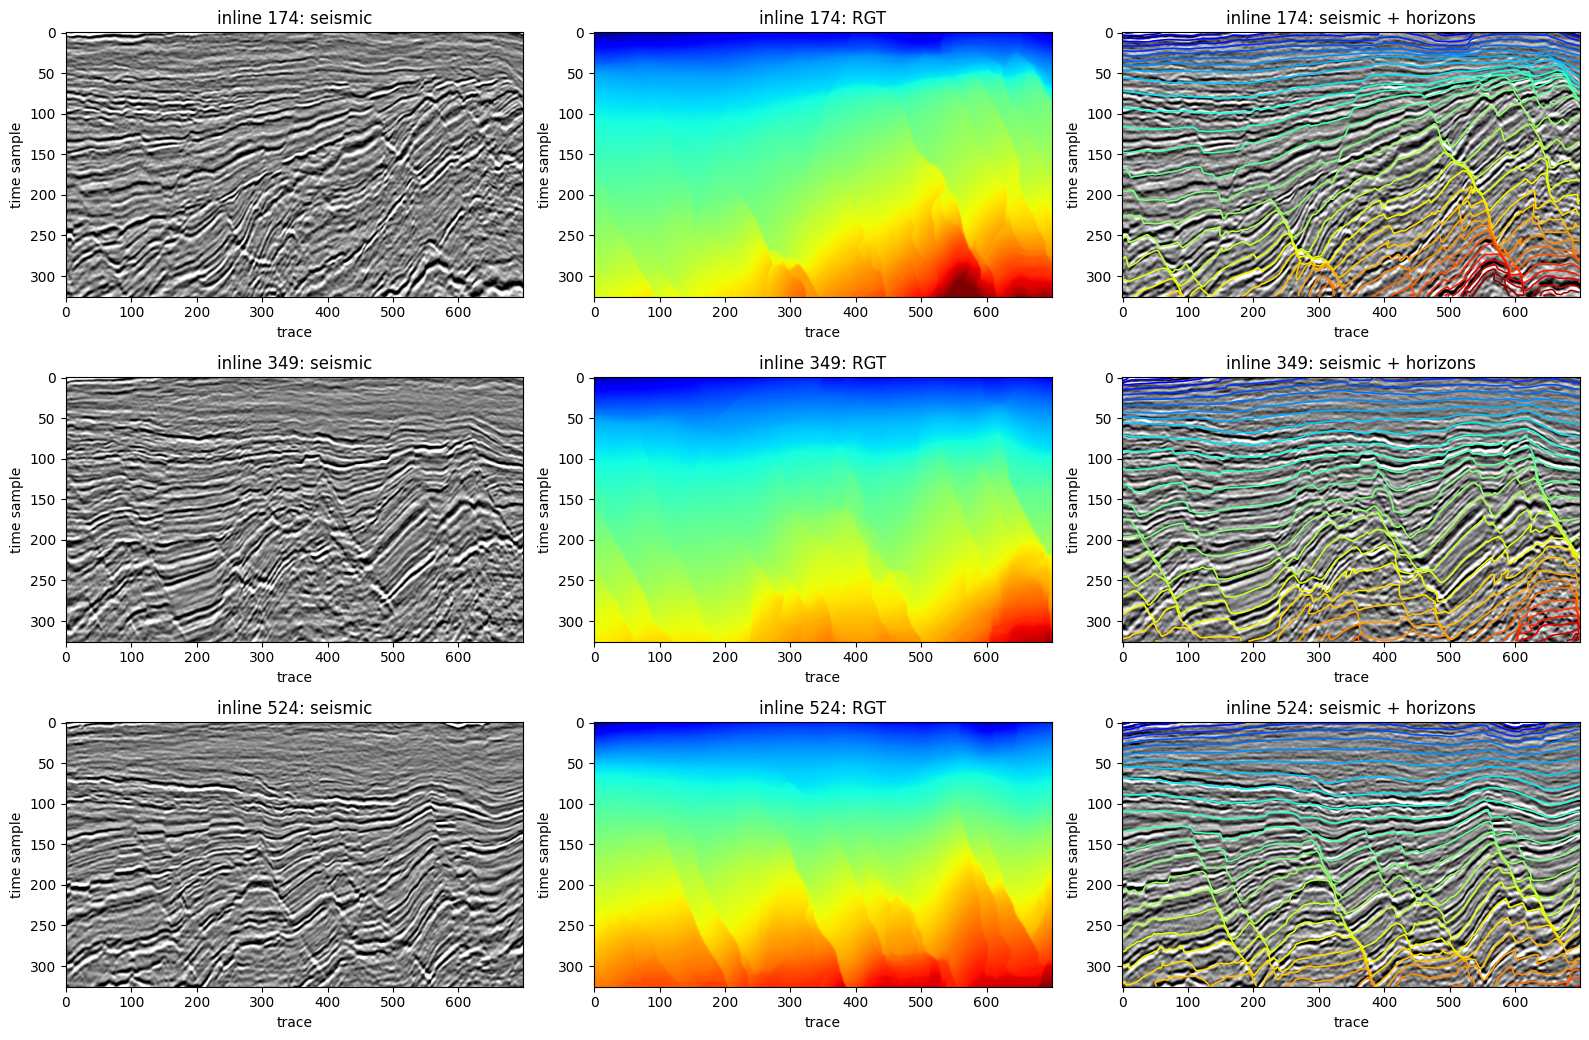

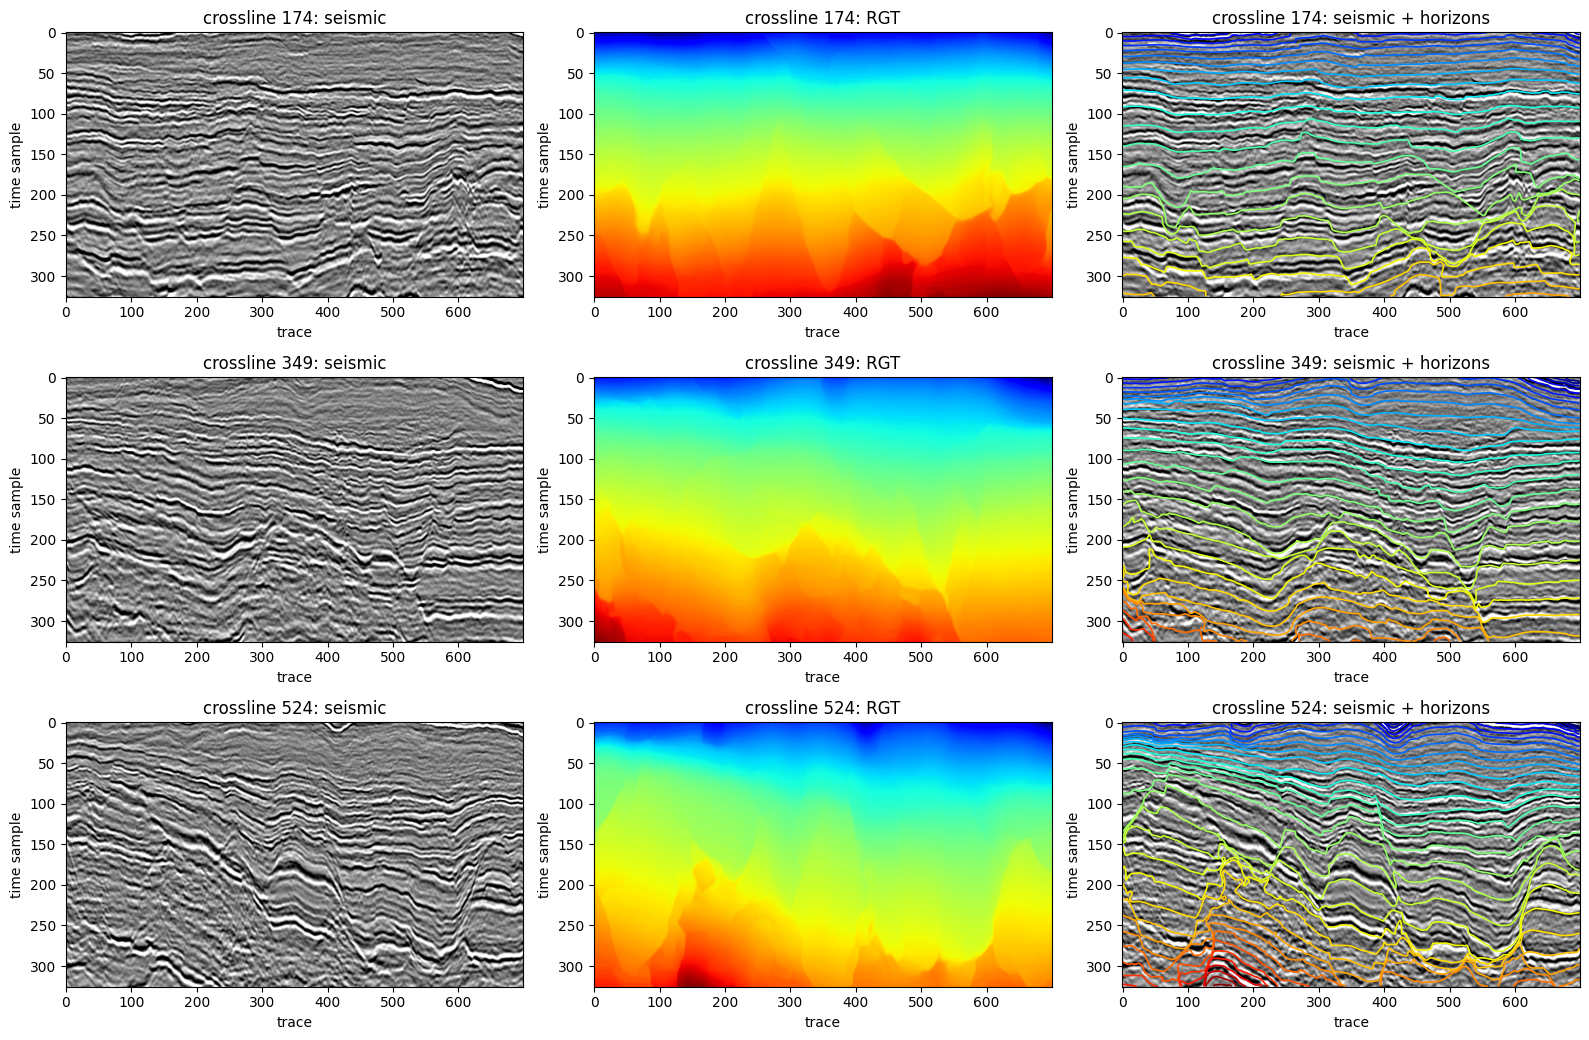

In [8]:
import matplotlib.pyplot as plt

rgt_hwt = rgt_volume.transpose(1, 2, 0)        # (inline, xline, time), same layout as seis
levels = np.linspace(0.02, 0.98, 35)

def show_sections(axis, n=3):
    idx = np.linspace(0, seis.shape[axis] - 1, n + 2, dtype=int)[1:-1]
    fig, axes = plt.subplots(n, 3, figsize=(16, 3.5 * n))
    for row, i in enumerate(idx):
        s = np.take(seis, i, axis=axis).T          # (time, lateral)
        r = np.take(rgt_hwt, i, axis=axis).T
        v = np.percentile(np.abs(s), 99)
        axes[row, 0].imshow(s, cmap="gray", aspect="auto", vmin=-v, vmax=v)
        axes[row, 1].imshow(r, cmap="jet", aspect="auto")
        axes[row, 2].imshow(s, cmap="gray", aspect="auto", vmin=-v, vmax=v)
        axes[row, 2].contour(r, levels=levels, cmap="jet", linewidths=1.2)
        name = "inline" if axis == 0 else "crossline"
        for ax, title in zip(axes[row], ("seismic", "RGT", "seismic + horizons")):
            ax.set_title(f"{name} {i}: {title}"); ax.set_xlabel("trace"); ax.set_ylabel("time sample")
    fig.tight_layout(); plt.show()

show_sections(axis=0)   # inlines
show_sections(axis=1)   # crosslines

## 8. (Optional) Map view of a few horizons

Traces horizons as surfaces through the whole 3D volume and plots their depth (time) as maps.

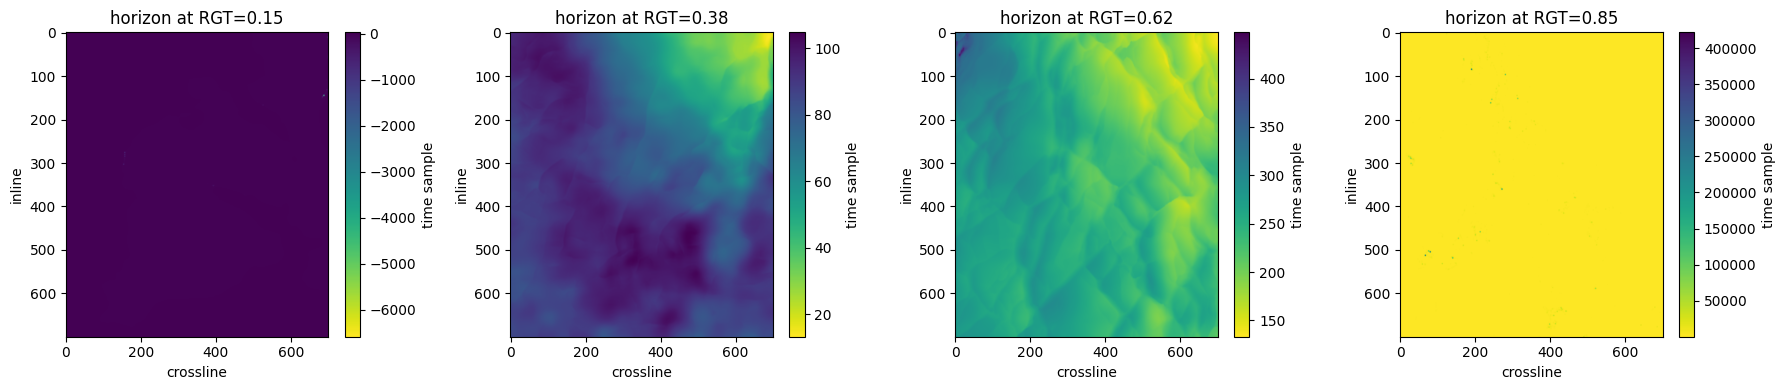

In [9]:
from rgt_helper import horizons_from_rgt

hu = np.linspace(0.15, 0.85, 4)                         # which RGT values to trace
hzs = horizons_from_rgt(sig=1.0, hu=hu, ux=rgt_hwt)     # (n_horizons, inline, xline)

fig, axes = plt.subplots(1, len(hu), figsize=(4.5 * len(hu), 4))
for ax, hz, u in zip(axes, hzs, hu):
    im = ax.imshow(hz, cmap="viridis_r", aspect="auto")
    ax.set_title(f"horizon at RGT={u:.2f}"); ax.set_xlabel("crossline"); ax.set_ylabel("inline")
    plt.colorbar(im, ax=ax, label="time sample")
fig.tight_layout(); plt.show()

## 9. Demo: Building a Low-Frequency Model guided by RGT
This demo shows how to interpolate a "well log" (located at a specific inline/crossline coordinate) across the entire 3D volume by mapping the physical depth (time sample) to geologic age (RGT) values.

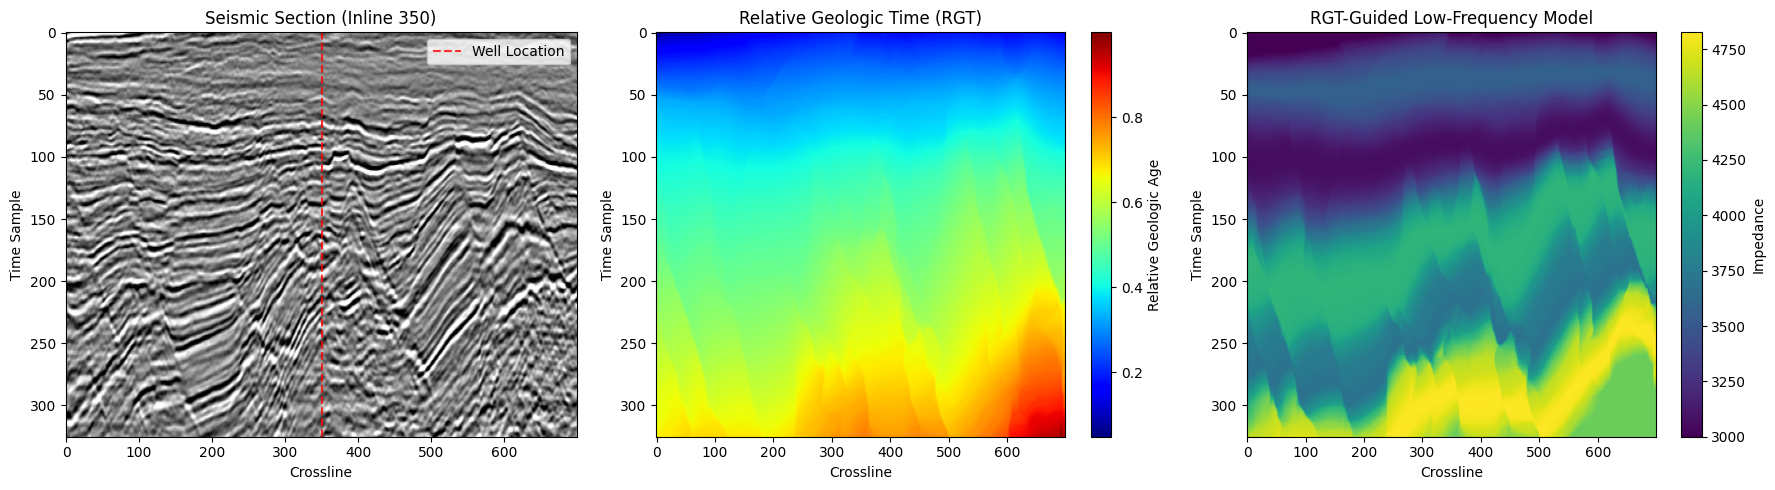

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define a mock well location in our 700x700 survey
well_inline = 350
well_xline = 350

# Extract the RGT profile at the well location (length 326)
well_rgt_profile = rgt_hwt[well_inline, well_xline, :]

# 2. Create a mock well log (e.g., P-Impedance or Velocity in m/s * g/cm3)
# We'll make it increase generally with depth but have some realistic layers
time_axis = np.arange(len(well_rgt_profile))
mock_well_impedance = 3000 + 5 * time_axis + 400 * np.sin(time_axis / 20)

# 3. Build the 3D Low-Frequency Model (LFM) guided by RGT
# We map: RGT value -> Well Impedance
# To do this safely, we sort the RGT values at the well to ensure monotonicity for interpolation
sort_idx = np.argsort(well_rgt_profile)
sorted_rgt = well_rgt_profile[sort_idx]
sorted_impedance = mock_well_impedance[sort_idx]

# Interpolate the well log across the entire 3D RGT volume
# np.interp expects 1D arrays, so we flatten, interpolate, and reshape
flat_rgt = rgt_hwt.flatten()
flat_lfm = np.interp(flat_rgt, sorted_rgt, sorted_impedance, left=sorted_impedance[0], right=sorted_impedance[-1])
lfm_volume = flat_lfm.reshape(rgt_hwt.shape) # (inline, xline, time)

# 4. Plot the results to compare the raw seismic, RGT, and RGT-guided Low Frequency Model
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# We'll view Inline 350 (passing directly through our well)
inline_idx = well_inline
s_sec = seis[inline_idx, :, :].T
r_sec = rgt_hwt[inline_idx, :, :].T
lfm_sec = lfm_volume[inline_idx, :, :].T
v = np.percentile(np.abs(s_sec), 99)

# Plot Seismic
im0 = axes[0].imshow(s_sec, cmap="gray", aspect="auto", vmin=-v, vmax=v)
axes[0].axvline(x=well_xline, color='red', linestyle='--', alpha=0.8, label='Well Location')
axes[0].set_title(f"Seismic Section (Inline {inline_idx})")
axes[0].legend()

# Plot RGT
im1 = axes[1].imshow(r_sec, cmap="jet", aspect="auto")
axes[1].set_title("Relative Geologic Time (RGT)")
plt.colorbar(im1, ax=axes[1], label="Relative Geologic Age")

# Plot RGT-guided Low-Frequency Model
im2 = axes[2].imshow(lfm_sec, cmap="viridis", aspect="auto")
axes[2].set_title("RGT-Guided Low-Frequency Model")
plt.colorbar(im2, ax=axes[2], label="Impedance")

for ax in axes:
    ax.set_xlabel("Crossline")
    ax.set_ylabel("Time Sample")

plt.tight_layout()
plt.show()

## 10. Load and Map your Custom Well CSV
Use this cell once you upload your `.csv` file containing `depth` and `AI` columns. It maps your custom physical depth to the seismic sample space.

In [12]:
import pandas as pd

# Placeholder name - change this to your uploaded file name!
WELL_CSV_FILE = "your_well_log.csv"

# Define the physical depth mapping parameters of your seismic volume here:
# For example, if sample index 0 is at 1200 meters, and each sample is 4 meters deep:
SEISMIC_START_DEPTH = 0.0
SEISMIC_DEPTH_STEP = 1.0

try:
    df_well = pd.read_csv(os.path.join(DATA_FOLDER, WELL_CSV_FILE))
    print("Successfully loaded well log data:")
    display(df_well.head())

    # Example of mapping physical depth to seismic time/depth index
    # index = (physical_depth - SEISMIC_START_DEPTH) / SEISMIC_DEPTH_STEP

except FileNotFoundError:
    print(f"Please upload '{WELL_CSV_FILE}' to your '{DATA_FOLDER}' folder to run this mapping setup.")


Please upload 'your_well_log.csv' to your '/content' folder to run this mapping setup.


In [14]:
# Approximate real-world geometry estimation for Poseidon sub-volume
inline_spacing = 18.75  # Poseidon inline bin size is often 18.75m or 25m
crossline_spacing = 12.5 # Poseidon crossline bin size is often 12.5m or 25m
sample_rate_ms = 4.0     # Typical temporal sample rate is 4ms TWT

# Calculate dimensions
total_inlines_m = seis.shape[0] * inline_spacing
total_crosslines_m = seis.shape[1] * crossline_spacing
total_time_ms = seis.shape[2] * sample_rate_ms

print("=== Approximate Real-World Geometry of Your Sub-Volume ===")
print(f"Inline coverage:   {seis.shape[0]} traces (~{total_inlines_m / 1000:.2f} km lateral extent)")
print(f"Crossline coverage: {seis.shape[1]} traces (~{total_crosslines_m / 1000:.2f} km lateral extent)")
print(f"Vertical coverage:  {seis.shape[2]} samples (~{total_time_ms:.1f} ms TWT depth range)")
print("=========================================================")
print("If you assume an average velocity of 2500 m/s for conversion to depth:")
approx_depth_extent_m = (total_time_ms / 1000.0) * 2500.0 / 2.0  # divided by 2 for one-way travel
print(f"Approximate physical depth interval: ~{approx_depth_extent_m:.1f} meters")

=== Approximate Real-World Geometry of Your Sub-Volume ===
Inline coverage:   700 traces (~13.12 km lateral extent)
Crossline coverage: 700 traces (~8.75 km lateral extent)
Vertical coverage:  326 samples (~1304.0 ms TWT depth range)
If you assume an average velocity of 2500 m/s for conversion to depth:
Approximate physical depth interval: ~1630.0 meters


## 11. Read and Inspect the Real Well Log File
This cell loads the uploaded Excel file `Norton_3_Export_AI.xlsx` to examine its column structure, units, and data ranges.

In [15]:
import pandas as pd
import os

excel_path = "/content/Norton_3_Export_AI.xlsx"

try:
    # Read the excel file to inspect its sheets
    xl = pd.ExcelFile(excel_path)
    print("Sheet names found in the Excel file:", xl.sheet_names)

    # Load the first sheet
    df_real_well = xl.parse(xl.sheet_names[0])
    print("\nFirst 5 rows of the dataset:")
    display(df_real_well.head())

    print("\nColumn names and data types:")
    print(df_real_well.dtypes)

    print("\nData summary statistics:")
    display(df_real_well.describe())
except Exception as e:
    print(f"An error occurred while loading the file: {e}")

Sheet names found in the Excel file: ['Sheet1']

First 5 rows of the dataset:


/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,Well:,NORTON_3
0,Depth,AI_Virgin
1,TVDss,AI
2,m,g/cm3_m/s
3,1445.341201,5621.29861
4,1448.084401,5735.04073



Column names and data types:
Well:       object
NORTON_3    object
dtype: object

Data summary statistics:


,Well:,NORTON_3
count,329,329
unique,329,329
top,Depth,AI_Virgin
freq,1,1


=== Cleaned Well Log Data ===
Total data points: 326
Depth Range: 1445.34 m to 2336.88 m
Acoustic Impedance Range: 5149.77 to 12183.40


/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,Depth,AI
0,1445.341201,5621.298610
1,1448.084401,5735.040730
2,1450.827601,5802.810826
3,1453.570801,6079.400069
4,1456.314001,5680.896562


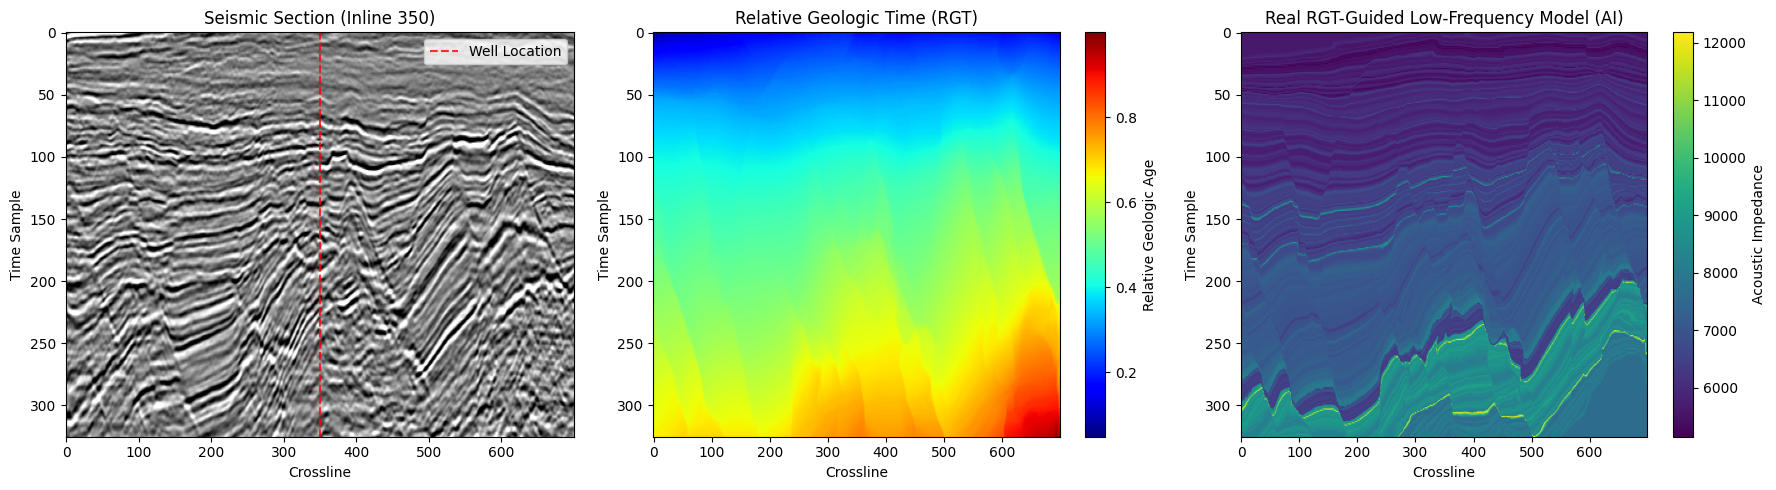

In [16]:
# 1. Read the Excel file properly, skipping the metadata rows
df_clean = pd.read_excel(excel_path, skiprows=3, names=['Depth', 'AI'])

# Ensure both columns are numeric
df_clean['Depth'] = pd.to_numeric(df_clean['Depth'], errors='coerce')
df_clean['AI'] = pd.to_numeric(df_clean['AI'], errors='coerce')
df_clean = df_clean.dropna().reset_index(drop=True)

print("=== Cleaned Well Log Data ===")
print(f"Total data points: {len(df_clean)}")
print(f"Depth Range: {df_clean['Depth'].min():.2f} m to {df_clean['Depth'].max():.2f} m")
print(f"Acoustic Impedance Range: {df_clean['AI'].min():.2f} to {df_clean['AI'].max():.2f}")
display(df_clean.head())

# 2. Resample the well log to match the 326 seismic samples
# We linearly map the well's physical depth to the 326 vertical seismic samples
seismic_samples = rgt_hwt.shape[2] # 326
mapped_depths = np.linspace(df_clean['Depth'].min(), df_clean['Depth'].max(), seismic_samples)
real_well_ai_resampled = np.interp(mapped_depths, df_clean['Depth'], df_clean['AI'])

# 3. Build the structurally guided 3D Low Frequency Model (LFM) from real data
# We'll assume the well is located at Inline 350, Crossline 350
well_inline = 350
well_xline = 350
well_rgt_profile = rgt_hwt[well_inline, well_xline, :]

# Sort by RGT to ensure monotonicity for interpolation
sort_idx = np.argsort(well_rgt_profile)
sorted_rgt = well_rgt_profile[sort_idx]
sorted_ai = real_well_ai_resampled[sort_idx]

# Interpolate across the entire 3D RGT volume
flat_rgt = rgt_hwt.flatten()
flat_lfm_real = np.interp(flat_rgt, sorted_rgt, sorted_ai, left=sorted_ai[0], right=sorted_ai[-1])
lfm_volume_real = flat_lfm_real.reshape(rgt_hwt.shape)

# 4. Plot the real RGT-guided Low Frequency Impedance Model
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

inline_idx = well_inline
s_sec = seis[inline_idx, :, :].T
r_sec = rgt_hwt[inline_idx, :, :].T
lfm_sec_real = lfm_volume_real[inline_idx, :, :].T
v = np.percentile(np.abs(s_sec), 99)

# Plot Seismic
im0 = axes[0].imshow(s_sec, cmap="gray", aspect="auto", vmin=-v, vmax=v)
axes[0].axvline(x=well_xline, color='red', linestyle='--', alpha=0.8, label='Well Location')
axes[0].set_title(f"Seismic Section (Inline {inline_idx})")
axes[0].legend()

# Plot RGT
im1 = axes[1].imshow(r_sec, cmap="jet", aspect="auto")
axes[1].set_title("Relative Geologic Time (RGT)")
plt.colorbar(im1, ax=axes[1], label="Relative Geologic Age")

# Plot Real RGT-guided Low-Frequency Model
im2 = axes[2].imshow(lfm_sec_real, cmap="viridis", aspect="auto")
axes[2].set_title("Real RGT-Guided Low-Frequency Model (AI)")
plt.colorbar(im2, ax=axes[2], label="Acoustic Impedance")

for ax in axes:
    ax.set_xlabel("Crossline")
    ax.set_ylabel("Time Sample")

plt.tight_layout()
plt.show()